In [3]:
from qutip import *
import numpy as np
import matplotlib.pyplot as plt

N_cav = 30 #(truncado)
N_atomos = 5
epsilon = .3
lamda = 1
g = lamda / 2*(np.sqrt(N_atomos)) # Acoplamiento

tiempo = 30
pasos = 300
a = tensor([destroy(N_cav)] + [qeye(2) for _ in range(0,  N_atomos)])

#Definimos a la lista de los operadores individuales:
sigmaz_list = [tensor([qeye(N_cav)] + [sigmaz() if j == i else qeye(2) for j in range(N_atomos)]) for i in range(N_atomos)]
sigmam_list = [tensor([qeye(N_cav)] + [sigmam() if j == i else qeye(2) for j in range(N_atomos)]) for i in range(N_atomos)]
sigmap_list = [tensor([qeye(N_cav)] + [sigmap() if j == i else qeye(2) for j in range(N_atomos)]) for i in range(N_atomos)]

#Ahora definimos a los operadores colectivos
J_z = sum(sigmaz_list)
J_m = sum(sigmam_list)
J_p = J_m.dag()

tlist = np.linspace(0, tiempo, pasos)

estado_inicial = tensor([basis(N_cav, 0)] + [basis(2,0) for _ in range(N_atomos)])
rho0 = ket2dm(estado_inicial)

Text(0, 0.5, 'Inversión Atómica por Átomo')

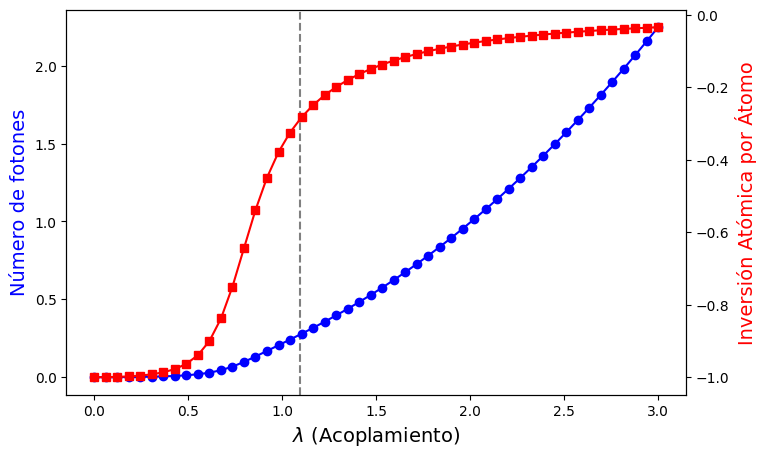

In [ ]:
lamdas = np.linspace(0, 3, 50) # Rango de acoplamiento (debe cruzar lambda_c)

# Parte del Hamiltoniano que no depende de lambda
H0 = a.dag() * a + (epsilon / 2) * J_z

n_fotones = []
inversion = []

for l in lamdas:
    g_eff = l / (2 * np.sqrt(N_atomos))
    H = H0 + g_eff * (a  + a.dag()) * (J_p + J_m)
    
    # Calculamos el estado fundamental (energía y ket)
    en, gs = H.groundstate()
    
    # Guardamos los valores esperados en el estado fundamental
    n_fotones.append(expect(a.dag() * a, gs)/N_atomos)
    inversion.append(expect(J_z, gs) / N_atomos)

fig, ax1 = plt.subplots(figsize=(8, 5))

# Punto crítico teórico para el modelo de Dicke
lambda_c = 2* np.sqrt(epsilon) 
ax1.axvline(lambda_c, color='gray', linestyle='--', label='Punto Crítico')

ax1.plot(lamdas, n_fotones, 'bo-', label='Fotones')
ax1.set_xlabel(r'$\lambda$ (Acoplamiento)', fontsize=14)
ax1.set_ylabel('Número de fotones', color='b', fontsize=14)

ax2 = ax1.twinx()
ax2.plot(lamdas, inversion, 'rs-', label='Inversión (Jz/N)')
ax2.set_ylabel('Inversión Atómica por Átomo', color='r', fontsize=14)


Text(0, 0.5, 'Inversión Atómica por Átomo')

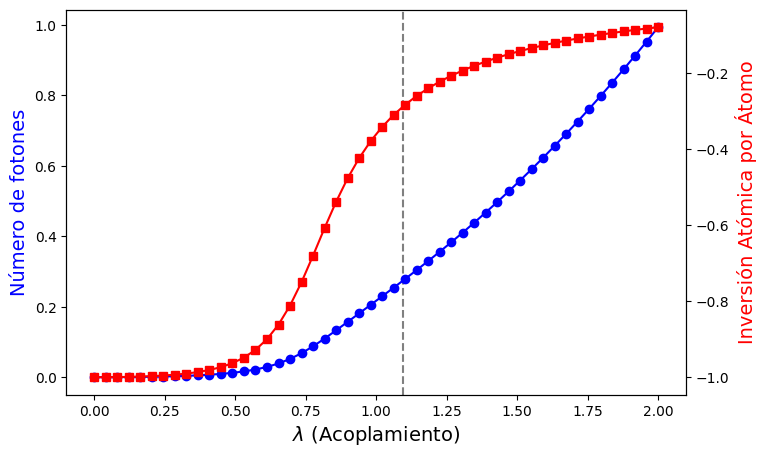

: 

In [ ]:
lamdas = np.linspace(0, 2, 50) # Rango de acoplamiento (debe cruzar lambda_c)

# Parte del Hamiltoniano que no depende de lambda
H0 = a.dag() * a + (epsilon / 2) * J_z

n_fotones = []
inversion = []

for l in lamdas:
    g_eff = l / (2 * np.sqrt(N_atomos))
    H = H0 + g_eff * (a  + a.dag()) * (J_p + J_m)
    
    # Calculamos el estado fundamental (energía y ket)
    en, gs = H.groundstate()
    
    # Guardamos los valores esperados en el estado fundamental
    n_fotones.append(expect(a.dag() * a, gs)/N_atomos)
    inversion.append(expect(J_z, gs) / N_atomos)

fig, ax1 = plt.subplots(figsize=(8, 5))

# Punto crítico teórico para el modelo de Dicke
lambda_c = 2* np.sqrt(epsilon) 
ax1.axvline(lambda_c, color='gray', linestyle='--', label='Punto Crítico')

ax1.plot(lamdas, n_fotones, 'bo-', label='Fotones')
ax1.set_xlabel(r'$\lambda$ (Acoplamiento)', fontsize=14)
ax1.set_ylabel('Número de fotones', color='b', fontsize=14)

ax2 = ax1.twinx()
ax2.plot(lamdas, inversion, 'rs-', label='Inversión (Jz/N)')
ax2.set_ylabel('Inversión Atómica por Átomo', color='r', fontsize=14)
